# 12 · xPass calibrado, peso da sombra e v4 com as três moedas · Cover Shadow Value (CSV)

Fase 9a do CRISP-DM (D42). A probabilidade de o passe chegar passa a ser um **xPass** aprendido com os 20 jogos abertos da SkillCorner (sem pose;
logístico com comprimento, avanço, distância mínima de um defesa à linha, nº de defesas a < 3 m da linha, distância do recetor e do portador ao adversário
mais próximo), e a sombra entra por cima, `logit p = base + γ · sombra`, com γ ajustado nos 2 jogos com pose. O contrafactual «sem sombra» é a sombra a 0.
A escolha (M2) não muda. Os critérios K1–K5 e a regra de decisão estão na D42, fixados antes de calcular; as tabelas abaixo só os aplicam.

Versões: `v3` (literatura), `v4` (D39), `v3_1_lit_<moeda>` (v3.1 do modelo físico da D40 com os parâmetros da literatura), `v3_1_xp_<moeda>` e `v4_xp_<moeda>` (esta fase).
Moedas: `xt`, `linhas`, `risco`. Só números, sem conclusões.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from footy.paths import output_dir

pd.options.display.float_format = "{:.4f}".format
pd.options.display.width = 220
pd.options.display.max_columns = 40
with open(output_dir("cover_shadow") / "xpass_v4.json", encoding="utf-8") as f:
    R = json.load(f)
K, X, S, T = R["criterios"], R["xpass"], R["sombra"], R["tabelas"]
MOEDAS = ["xt", "linhas", "risco"]
cumpre = lambda b: "cumpre" if b else "não cumpre"
print("tempo de cálculo das tabelas (s):", round(R["tempo_s"]))

tempo de cálculo das tabelas (s): 36


## 1. K1 · xPass base (20 jogos, um de fora de cada vez)

Passes rasteiros da D37 (os da 8g), resultado `pass_outcome` (1 = chegou), frame de tracking do passe, sem pose. Ajuste sem penalização; cada jogo é previsto com o ajuste dos outros 19.
Critério K1: ECE ≤ 0,03 (10 decis, 20 dobras juntas) e log-loss melhor que a taxa base em ≥ 16 dos 20 jogos.

### 1.1 Coeficientes (todos os jogos; escala original das variáveis)

In [2]:
c = pd.Series(X["coeficientes_20_jogos"], name="coeficiente").to_frame()
display(c)
print("passes:", X["n_passes"], "| taxa de sucesso:", round(X["taxa_sucesso"], 4))

,coeficiente
intercepto,1.5105
comprimento,-0.1013
avanco,-0.0155
dist_linha,0.0449
n_perto,-0.5270
dist_recetor,0.2785
dist_portador,0.0868


passes: 14584 | taxa de sucesso: 0.8494


### 1.2 Por jogo: log-loss do xPass e da taxa base (fora da amostra)

In [3]:
t = pd.DataFrame(X["por_jogo"]).set_index("jogo")
t["melhoria"] = t["log_loss_taxa_base"] - t["log_loss_modelo"]
display(t)
print("média da melhoria:", round(t["melhoria"].mean(), 4), "| jogos em que o xPass bate a taxa base:", int((t["melhoria"] > 0).sum()), "de", len(t))

,passes,taxa_sucesso,log_loss_modelo,log_loss_taxa_base,melhoria
jogo,,,,,
1874553,758,0.8549,0.2491,0.4143,0.1652
1886347,791,0.8723,0.2559,0.3843,0.1284
1899585,660,0.8258,0.3152,0.4649,0.1497
1925299,828,0.8696,0.2655,0.3891,0.1236
1927964,942,0.9183,0.1781,0.3072,0.1292
1953632,775,0.8968,0.1913,0.3428,0.1515
1959846,744,0.8414,0.3114,0.4376,0.1262
1986691,701,0.8759,0.2536,0.3782,0.1246
1996435,806,0.8536,0.3040,0.4165,0.1125


média da melhoria: 0.1403 | jogos em que o xPass bate a taxa base: 20 de 20


### 1.3 Calibração fora da amostra (decis; 20 dobras juntas)

,decil,n,previsto,observado
0,0,1459,0.3329,0.3427
1,1,1458,0.6677,0.6550
2,2,1458,0.8030,0.7929
3,3,1459,0.8743,0.8759
4,4,1458,0.9226,0.9246
5,5,1458,0.9531,0.9520
6,6,1459,0.9716,0.9781
7,7,1458,0.9828,0.9829
8,8,1458,0.9901,0.9966
9,9,1459,0.9953,0.9938


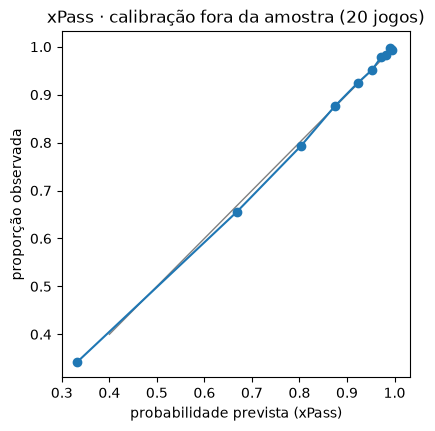

{'n': 14584, 'log_loss': 0.2845, 'brier': 0.0869, 'ece': 0.0052}
K1: ECE 0.0052 (limite 0.03) | jogos a bater a taxa base 20/20 (mínimo 16) → cumpre


In [4]:
curva = pd.DataFrame(X["curva_de_calibracao"])
display(curva)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0.4, 1], [0.4, 1], color="grey", lw=1)
ax.plot(curva["previsto"], curva["observado"], "o-")
ax.set_xlabel("probabilidade prevista (xPass)"); ax.set_ylabel("proporção observada"); ax.set_title("xPass · calibração fora da amostra (20 jogos)")
plt.show()
print({k: round(v, 4) for k, v in X["metricas_juntas"].items()})
k1 = K["K1"]
print(f"K1: ECE {k1['ece']:.4f} (limite {k1['limite_ece']}) | jogos a bater a taxa base {k1['jogos_a_bater_a_taxa_base']}/20 (mínimo {k1['minimo_de_jogos']}) → {cumpre(k1['cumpre'])}")

## 2. K2 · peso da sombra nos 2 jogos com pose

Passes do modelo (D37) dos 2 jogos com pose, frame da escolha, linha do recetor visado: `sombra` = 1 − `p_sombras` da v3 (tronco, literatura) ou a versão virada para a bola.
Base = xPass ajustado nos outros 19 jogos (offset); γ sem termo independente. γ ajustado num jogo e testado no outro, e ao contrário. K2: ECE ≤ 0,04 em cada jogo de teste.

### 2.1 γ com os dois jogos juntos (IC 95 % pelo erro-padrão de Fisher)

In [5]:
g = pd.DataFrame(S["gamma_dois_jogos"]).T
g["ic95_inf"] = g["ic95"].map(lambda v: v[0]); g["ic95_sup"] = g["ic95"].map(lambda v: v[1])
display(g[["gamma", "erro_padrao", "ic95_inf", "ic95_sup", "n"]])

,gamma,erro_padrao,ic95_inf,ic95_sup,n
tronco,-0.3736,0.2966,-0.9549,0.2078,1408
bola,-0.3402,0.2727,-0.8748,0.1944,1408


### 2.2 Fora da amostra: sem sombra (γ = 0), sombra pelo tronco e sombra virada para a bola

In [6]:
linhas = []
for nome, d in S["direcoes"].items():
    for modelo, m in d["metricas"].items():
        linhas.append({"ajuste → teste": nome, "n_teste": d["n_teste"], "modelo": modelo, "log_loss": m["log_loss"], "brier": m["brier"], "ece": m["ece"],
                       "γ tronco": d["gamma_tronco"], "γ bola": d["gamma_bola"]})
display(pd.DataFrame(linhas).set_index(["ajuste → teste", "modelo"]))
print("juntos (as duas direções):")
display(pd.DataFrame(S["metricas_juntas"]).T)
k2 = K["K2"]
print("ECE por jogo de teste (sombra pelo tronco):", {int(k): round(v, 4) for k, v in k2["ece_por_jogo_de_teste"].items()}, "| limite", k2["limite_ece"], "→", cumpre(k2["cumpre"]))

n_teste  log_loss  brier    ece  γ tronco  γ bola
ajuste → teste   modelo                                                       
1925299->1996435 sem_sombra      684    0.2953 0.0876 0.0314   -0.8257 -0.6726
                 tronco          684    0.2985 0.0890 0.0406   -0.8257 -0.6726
                 bola            684    0.2973 0.0885 0.0408   -0.8257 -0.6726
1996435->1925299 sem_sombra      724    0.2415 0.0724 0.0269    0.0335 -0.0661
                 tronco          724    0.2417 0.0725 0.0269    0.0335 -0.0661
                 bola            724    0.2411 0.0723 0.0253    0.0335 -0.0661

juntos (as duas direções):


,n,log_loss,brier,ece
sem_sombra,1408.0000,0.2676,0.0798,0.0202
tronco,1408.0000,0.2693,0.0805,0.0247
bola,1408.0000,0.2684,0.0802,0.0254


ECE por jogo de teste (sombra pelo tronco): {1996435: 0.0406, 1925299: 0.0269} | limite 0.04 → não cumpre


### 2.3 Calibração por jogo de teste (decis; sombra pelo tronco)

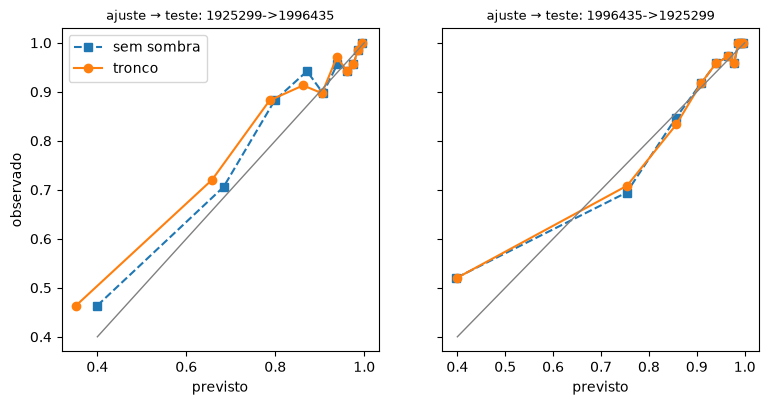

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(9, 4.2), sharey=True)
for ax, (nome, d) in zip(axs, S["direcoes"].items()):
    for modelo, estilo in (("sem_sombra", "s--"), ("tronco", "o-")):
        c = pd.DataFrame(d["curvas"][modelo])
        ax.plot(c["previsto"], c["observado"], estilo, label=modelo.replace("_", " "))
    ax.plot([0.4, 1], [0.4, 1], color="grey", lw=1); ax.set_title(f"ajuste → teste: {nome}", fontsize=9); ax.set_xlabel("previsto")
axs[0].set_ylabel("observado"); axs[0].legend()
plt.show()

### 2.4 Tronco vs bola: diferença de log-loss por passe (tronco − bola; negativa = tronco melhor), IC 95 % por bootstrap sobre os passes

In [8]:
display(pd.Series(S["tronco_menos_bola_log_loss"], name="tronco − bola").to_frame())

,tronco − bola
media,0.0009
diferenca,0.0009
ic95_inf,-0.0006
ic95_sup,0.0026


### 2.5 Correlação entre a sombra e as variáveis da base (passes dos 2 jogos com pose)

In [9]:
display(pd.DataFrame(S["matriz_de_correlacao"]).loc[["sombra_tronco", "sombra_bola", "comprimento", "avanco", "dist_linha", "n_perto", "dist_recetor", "dist_portador"],
                                                  ["sombra_tronco", "sombra_bola", "comprimento", "avanco", "dist_linha", "n_perto", "dist_recetor", "dist_portador"]])
print("diferença máxima entre a sombra recalculada e a de `escolhas_v3` (tronco):", S["sombra_tronco_vs_escolhas"])

,sombra_tronco,sombra_bola,comprimento,avanco,dist_linha,n_perto,dist_recetor,dist_portador
sombra_tronco,1.0000,0.8861,0.0636,0.1136,-0.3176,0.3949,-0.2485,-0.1698
sombra_bola,0.8861,1.0000,0.0907,0.1458,-0.3560,0.4643,-0.2661,-0.1768
comprimento,0.0636,0.0907,1.0000,0.1976,0.0066,0.0652,0.4002,0.2354
avanco,0.1136,0.1458,0.1976,1.0000,-0.2379,0.1640,-0.3297,0.2227
dist_linha,-0.3176,-0.3560,0.0066,-0.2379,1.0000,-0.6132,0.6019,0.5291
n_perto,0.3949,0.4643,0.0652,0.1640,-0.6132,1.0000,-0.5009,-0.3883
dist_recetor,-0.2485,-0.2661,0.4002,-0.3297,0.6019,-0.5009,1.0000,0.3867
dist_portador,-0.1698,-0.1768,0.2354,0.2227,0.5291,-0.3883,0.3867,1.0000


diferença máxima entre a sombra recalculada e a de `escolhas_v3` (tronco): 6.027353729454177e-06


## 3. K3–K5 por moeda (v4 com o xPass)

K3: % de momentos com v < 0 ≤ 10 % e com D < 0 ≤ 25 % (entre os momentos com defesas em C, os dois jogos juntos) e D total ≥ 0 nos dois jogos.
K4: ameaça negada média por momento em bloco alto + médio ≥ 25 % da do bloco baixo. K5: C06 → Jelacic e C03 → Klimala com o maior Shapley total no lance.

In [10]:
linhas = []
for m in MOEDAS:
    r = K["por_moeda"][m]
    linhas.append({"moeda": m,
                   "K1": cumpre(K["K1"]["cumpre"]), "K2": cumpre(K["K2"]["cumpre"]),
                   "K3": cumpre(r["k3"]["cumpre"]), "K4": cumpre(r["k4"]["cumpre"]), "K5": cumpre(r["k5"]["cumpre"]),
                   "todos": cumpre(r["todos_cumprem"])})
display(pd.DataFrame(linhas).set_index("moeda"))
print("veredicto (regra da D42):", K["veredicto"]["decisao"])

,K1,K2,K3,K4,K5,todos
moeda,,,,,,
xt,cumpre,não cumpre,não cumpre,não cumpre,cumpre,não cumpre
linhas,cumpre,não cumpre,não cumpre,cumpre,cumpre,não cumpre
risco,cumpre,não cumpre,não cumpre,não cumpre,cumpre,não cumpre


veredicto (regra da D42): v4 não aceite: o artigo segue com a v3.1


### 3.1 K3 · valores

In [11]:
linhas = []
for m in MOEDAS:
    r = K["por_moeda"][m]["k3"]
    linhas.append({"moeda": m, "momentos com defesas em C": r["momentos_com_defesas_em_C"], "% v < 0": r["pct_v_negativa"], "% D < 0": r["pct_D_negativa"],
                   **{f"D total {j}": v for j, v in r["D_total_por_jogo"].items()}, "cumpre": cumpre(r["cumpre"])})
display(pd.DataFrame(linhas).set_index("moeda"))

,momentos com defesas em C,% v < 0,% D < 0,D total 1925299,D total 1996435,cumpre
moeda,,,,,,
xt,15880,31.4673,34.7922,2.0939,1.4490,não cumpre
linhas,15880,30.7179,33.2431,340.2565,354.2350,não cumpre
risco,15880,70.5856,79.5340,-0.3473,-1.5049,não cumpre


### 3.2 K4 · valores

In [12]:
linhas = []
for m in MOEDAS:
    r = K["por_moeda"][m]["k4"]
    linhas.append({"moeda": m, "média alto+médio": r["media_alto_e_medio"], "momentos alto+médio": r["momentos_alto_e_medio"], "média baixo": r["media_baixo"],
                   "momentos baixo": r["momentos_baixo"], "razão": r["razao"], "cumpre": cumpre(r["cumpre"])})
display(pd.DataFrame(linhas).set_index("moeda"))

,média alto+médio,momentos alto+médio,média baixo,momentos baixo,razão,cumpre
moeda,,,,,,
xt,0.0000,9899,0.0007,5152,0.0673,não cumpre
linhas,0.0533,9899,0.0613,5152,0.8693,cumpre
risco,-0.0002,9899,0.0005,5152,-0.3102,não cumpre


### 3.3 K5 · Shapley total (I + D) por defesa nos lances C06 e C03, por moeda (só os 5 maiores)

In [13]:
for m in MOEDAS:
    for lance, r in K["por_moeda"][m]["k5"]["lances"].items():
        top = dict(list(r["shapley"].items())[:5])
        print(m, lance, "| esperado:", r["esperado"], "| maior:", r["maior"], "|", cumpre(r["cumpre"]), "|", {k: round(v, 5) for k, v in top.items()})

xt C06 | esperado: Jelacic | maior: K. Jelacic | cumpre | {'K. Jelacic': 2e-05}
xt C03 | esperado: Klimala | maior: P. Klimala | cumpre | {'P. Klimala': 0.00038}
linhas C06 | esperado: Jelacic | maior: K. Jelacic | cumpre | {'K. Jelacic': 0.02453}
linhas C03 | esperado: Klimala | maior: P. Klimala | cumpre | {'P. Klimala': 0.23684}
risco C06 | esperado: Jelacic | maior: K. Jelacic | cumpre | {'K. Jelacic': -0.00015}
risco C03 | esperado: Klimala | maior: P. Klimala | cumpre | {'P. Klimala': 0.00023}


## 4. Por fase defensiva e por terço, por moeda

Momentos com alguma linha avaliada, os dois jogos juntos. «Média por momento» = soma de v / nº de momentos; «% negada» = soma de v / soma de E(∅) (na v3 e v3.1, `negada / disponível`).

In [14]:
VERS = ["v3", "v4"] + [f"{a}_{m}" for a in ("v3_1_lit", "v3_1_xp", "v4_xp") for m in MOEDAS]
def tab(nome, formato="{:.5f}"):
    t = pd.DataFrame(T[nome]).set_index(nome.split("_")[0])
    return t[VERS]
print("média de v por momento · fase defensiva"); display(tab("fase_media_por_momento"))
print("% negada · fase defensiva"); display(tab("fase_pct_negada"))
print("momentos · fase defensiva"); display(tab("fase_momentos").astype("Int64"))

média de v por momento · fase defensiva


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
fase,,,,,,,,,,,
NaN,0.0000,-0.0000,0.0000,0.0000,0.0227,0.0000,0.0000,0.0045,-0.0000,-0.0164,-0.0002
chaotic,0.0083,0.0002,0.0013,0.9517,0.0311,0.0003,0.1346,0.0034,0.0001,0.0527,-0.0001
defending_direct,0.0033,0.0001,0.0009,1.5484,0.0257,0.0001,0.2211,0.0029,0.0000,0.1651,-0.0004
defending_quick_break,0.0467,0.0037,0.0089,0.2651,0.0162,0.0023,0.0360,0.0033,0.0011,0.0124,0.0009
defending_set_play,0.1166,0.0046,0.0118,1.0518,0.0330,0.0046,0.3077,0.0079,0.0014,0.0433,0.0008
defending_transition,0.0113,0.0012,0.0038,0.4757,0.0165,0.0008,0.0611,0.0022,0.0007,0.0341,0.0006
high_block,0.0024,0.0001,0.0005,0.7183,0.0204,0.0001,0.1402,0.0024,0.0000,0.0562,-0.0003
low_block,0.0254,0.0021,0.0060,0.8359,0.0126,0.0014,0.1684,0.0023,0.0007,0.0613,0.0005
medium_block,0.0046,0.0001,0.0007,0.6127,0.0081,0.0002,0.1497,0.0012,0.0001,0.0516,-0.0001


% negada · fase defensiva


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
fase,,,,,,,,,,,
NaN,0.0040,-16.1560,0.0030,0.0030,NaN,0.0010,0.0000,NaN,-16.4300,-13.5550,NaN
chaotic,53.6160,12.1930,21.7400,23.7320,NaN,5.0630,3.2470,NaN,4.4850,5.9510,NaN
defending_direct,24.1650,12.3320,19.6790,29.2310,NaN,2.9130,3.6570,NaN,1.0410,13.5560,NaN
defending_quick_break,53.1860,35.4040,37.4550,20.0840,27048.6500,8.5850,2.5330,54.7430,14.5920,3.0370,17.8370
defending_set_play,54.0530,43.3270,39.3370,23.1250,NaN,8.8810,5.2340,NaN,13.3870,3.2550,16.9880
defending_transition,39.2780,33.5710,33.8370,21.5890,NaN,6.7720,2.6290,NaN,21.1720,5.7510,225.9590
high_block,24.9080,10.6810,14.7580,16.7640,NaN,2.3050,2.5860,NaN,3.5940,5.0520,NaN
low_block,46.2490,33.3760,33.6960,22.5460,NaN,6.6060,3.9560,NaN,14.6670,6.7820,19.4040
medium_block,30.4620,11.4740,14.5840,15.3210,NaN,2.8360,2.8120,NaN,4.7720,4.9410,NaN


momentos · fase defensiva


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
fase,,,,,,,,,,,
NaN,4,4,4,4,4,4,4,4,4,4,4
chaotic,904,975,904,904,904,904,904,904,975,975,975
defending_direct,26,28,26,26,26,26,26,26,28,28,28
defending_quick_break,380,400,380,380,380,380,380,380,400,400,400
defending_set_play,246,271,246,246,246,246,246,246,271,271,271
defending_transition,315,331,315,315,315,315,315,315,331,331,331
high_block,3354,3587,3349,3349,3349,3349,3349,3349,3587,3587,3587
low_block,4938,5152,4938,4938,4938,4938,4938,4938,5152,5152,5152
medium_block,6138,6312,6137,6137,6137,6137,6137,6137,6312,6312,6312


In [15]:
print("média de v por momento · terço"); display(tab("terco_media_por_momento"))
print("% negada · terço"); display(tab("terco_pct_negada"))
print("momentos · terço"); display(tab("terco_momentos").astype("Int64"))

média de v por momento · terço


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
terco,,,,,,,,,,,
attacking_third,0.0387,0.0031,0.0081,0.6761,0.0144,0.0020,0.1218,0.0029,0.0011,0.0465,0.0009
defensive_third,0.0025,0.0001,0.0005,0.7196,0.0207,0.0001,0.1378,0.0024,0.0000,0.0549,-0.0003
middle_third,0.0073,0.0003,0.0013,0.7410,0.0087,0.0003,0.1772,0.0014,0.0001,0.0585,-0.0000


% negada · terço


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
terco,,,,,,,,,,,
attacking_third,51.4940,37.8330,37.6460,25.1130,NaN,7.8940,4.3010,56.5020,16.2180,6.4660,20.2940
defensive_third,25.3210,10.4400,14.1250,16.7880,NaN,2.2380,2.5690,NaN,3.3380,5.1510,NaN
middle_third,33.6040,13.6960,18.7630,17.4070,NaN,3.5940,3.2030,NaN,5.7070,5.3950,NaN


momentos · terço


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
terco,,,,,,,,,,,
attacking_third,4001,4197,4001,4001,4001,4001,4001,4001,4197,4197,4197
defensive_third,5352,5674,5347,5347,5347,5347,5347,5347,5674,5674,5674
middle_third,6952,7189,6951,6951,6951,6951,6951,6951,7189,7189,7189


## 5. Totais por jogo e versão (momentos com alguma linha)

In [16]:
t = pd.DataFrame(T["totais"])
display(t.set_index(["jogo", "versao"]))

momentos         E0         v  pct_negada  pct_v_negativa        I        D  pct_D_negativa
jogo    versao                                                                                                      
1925299 v3                   8568   266.0772  124.8168     46.9100          0.0000      NaN      NaN             NaN
        v4                   8915    27.7410    9.3776     33.8039         28.5474   8.0062   1.3714         42.4790
        v3_1_lit_xt          8563    81.2434   24.9748     30.7407          0.0000      NaN      NaN             NaN
        v3_1_lit_linhas      8563 30481.7361 5453.6616     17.8916          0.0000      NaN      NaN             NaN
        v3_1_lit_risco       8563  -173.9503  107.5283    -61.8155          0.0000      NaN      NaN             NaN
        v3_1_xp_xt           8563    98.2013    6.1501      6.2627          0.0000      NaN      NaN             NaN
        v3_1_xp_linhas       8563 36534.3781 1065.4886      2.9164          0.0000      NaN      NaN             NaN
        v3_1_xp_risco        8563  -115.9976   16.0265    -13.8162          0.0000      NaN      NaN             NaN
        v4_xp_xt             8915    22.8926    3.1401     13.7165         26.4274   1.0462   2.0939         29.2653
        v4_xp_linhas         8915  8102.5133  446.0491      5.5051         26.1245 105.7926 340.2565         28.3567
        v4_xp_risco          8915    -0.7750    1.5543   -200.5705         65.6534   1.9016  -0.3473         73.3932
1996435 v3                   7737   239.3464   94.3474     39.4188          0.0000      NaN      NaN             NaN
        v4                   8145    25.7960    6.1200     23.7247         30.1903   5.8319   0.2881         44.6041
        v3_1_lit_xt          7736    72.3598   19.1053     26.4031          0.0000      NaN      NaN             NaN
        v3_1_lit_linhas      7736 32796.6329 6249.5431     19.0554          0.0000      NaN      NaN             NaN
        v3_1_lit_risco       7736  -232.3487  121.3857    -52.2429          0.0000      NaN      NaN             NaN
        v3_1_xp_xt           7736    90.8200    4.5775      5.0402          0.0000      NaN      NaN             NaN
        v3_1_xp_linhas       7736 41942.1610 1390.5646      3.3154          0.0000      NaN      NaN             NaN
        v3_1_xp_risco        7736  -168.8543   17.4976    -10.3626          0.0000      NaN      NaN             NaN
        v4_xp_xt             8145    21.7295    2.1765     10.0164         32.4248   0.7275   1.4490         35.8011
        v4_xp_linhas         8145  8754.6193  480.9436      5.4936         31.2953 126.7086 354.2350         33.7753
        v4_xp_risco          8145    -5.1493    0.2830     -5.4962         65.7581   1.7879  -1.5049         74.7330

## 6. Lances C06, C03, D01–D03 e W04 em todas as versões

Totais do momento (E(∅), E(C), I, D, v; I e D só na v4) e Shapley por defesa (I + D na v4).

In [17]:
for nome, l in R["lances"].items():
    print(f"=== {nome} · jogo {l['jogo']} · frame {l['frame']}")
    display(pd.DataFrame(l["totais"]))
    display(pd.DataFrame(l["shapley"]))

=== C06 · jogo 1925299 · frame 12660


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
E0,0.0344,0.0020,0.0070,4.3394,-0.0262,0.0099,6.4699,-0.0174,0.0020,1.3566,-0.0006
EC,0.0224,0.0020,0.0062,3.6905,-0.0284,0.0096,6.2024,-0.0182,0.0019,1.3321,-0.0004
I,NaN,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0123,0.0000
D,NaN,-0.0000,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0123,-0.0002
v,0.0120,-0.0000,0.0008,0.6489,0.0021,0.0003,0.2675,0.0009,0.0000,0.0245,-0.0002


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
F. Bérenguer,0.0003,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
K. Jelacic,0.0043,-0.0000,0.0008,0.6489,0.0021,0.0003,0.2675,0.0009,0.0000,0.0245,-0.0002
A. Zimarino,0.0074,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


=== C03 · jogo 1996435 · frame 39646


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
E0,0.0274,0.0013,0.0092,7.8858,-0.0424,0.0148,13.1288,-0.0144,0.0014,1.2023,-0.0002
EC,0.0202,0.0007,0.0067,6.0853,-0.0551,0.0146,12.9518,-0.0155,0.0010,0.9655,-0.0004
I,NaN,0.0004,NaN,NaN,NaN,NaN,NaN,NaN,0.0000,0.0170,0.0001
D,NaN,0.0002,NaN,NaN,NaN,NaN,NaN,NaN,0.0004,0.2198,0.0001
v,0.0072,0.0006,0.0026,1.8005,0.0126,0.0002,0.1770,0.0012,0.0004,0.2368,0.0002


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
P. Klimala,0.0042,0.0006,0.0026,1.8005,0.0126,0.0002,0.1770,0.0012,0.0004,0.2368,0.0002
J. Lolley,0.0030,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


... (8 outputs left out)

,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
A. Ouahim,0.0000,-0.0080,0.0000,0.0000,0.0021,0.0000,0.0000,0.0002,-0.0055,0.0000,-0.0054
Léo Sena,0.0464,-0.0053,0.0005,0.0000,0.0006,0.0034,0.0000,0.0043,-0.0031,0.0000,-0.0032
J. Courtney-Perkins,0.2212,-0.0007,0.0060,0.0000,0.0063,0.0149,0.0000,0.0155,-0.0027,0.0000,-0.0029
A. Cáceres,0.0039,-0.0007,0.0000,0.0000,0.0000,0.0003,0.0000,0.0004,-0.0004,0.0000,-0.0005
C. Hollman,0.0104,-0.0013,0.0000,0.0000,0.0000,0.0003,0.0000,0.0004,-0.0009,0.0000,-0.0009
A. Segecic,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


=== W04 · jogo 1996435 · frame 45252


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
E0,0.2905,0.0963,0.1347,0.0000,0.1097,0.1299,0.0000,0.1070,0.0657,0.0000,0.0607
EC,0.2540,0.1119,0.1322,0.0000,0.1036,0.1273,0.0000,0.1033,0.0758,0.0000,0.0708
I,NaN,0.0008,NaN,NaN,NaN,NaN,NaN,NaN,0.0002,0.0000,0.0002
D,NaN,-0.0163,NaN,NaN,NaN,NaN,NaN,NaN,-0.0102,0.0000,-0.0104
v,0.0365,-0.0156,0.0025,0.0000,0.0062,0.0026,0.0000,0.0037,-0.0101,0.0000,-0.0101


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
Léo Sena,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000,-0.0000
J. Courtney-Perkins,0.0186,-0.0087,0.0017,0.0000,0.0051,0.0017,0.0000,0.0023,-0.0049,0.0000,-0.0048
R. Grant,0.0116,-0.0040,0.0005,0.0000,0.0007,0.0006,0.0000,0.0009,-0.0030,0.0000,-0.0031
C. Hollman,0.0063,-0.0028,0.0003,0.0000,0.0004,0.0003,0.0000,0.0005,-0.0022,0.0000,-0.0023
A. Segecic,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


## 7. ρ de Spearman por jogador dentro da posição, entre versões e moedas

Média ponderada (e mínimo por posição), os dois jogos juntos.

In [18]:
VERS_RHO = list(R["rho_por_posicao"]["media"].keys())
print("ρ médio"); display(pd.DataFrame(R["rho_por_posicao"]["media"]).loc[VERS_RHO, VERS_RHO])
print("ρ mínimo"); display(pd.DataFrame(R["rho_por_posicao"]["minimo"]).loc[VERS_RHO, VERS_RHO])

ρ médio


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
v3,1.0000,0.7360,0.8710,0.7190,0.5140,0.9520,0.7760,0.7090,0.5090,0.4920,0.0000
v4,0.7360,1.0000,0.7670,0.5310,0.3390,0.8550,0.5440,0.5010,0.7310,0.4780,0.2810
v3_1_lit_xt,0.8710,0.7670,1.0000,0.7370,0.5240,0.8560,0.7130,0.6320,0.5250,0.4970,0.0450
v3_1_lit_linhas,0.7190,0.5310,0.7370,1.0000,0.8100,0.6780,0.8680,0.8570,0.3510,0.6100,-0.2010
v3_1_lit_risco,0.5140,0.3390,0.5240,0.8100,1.0000,0.4360,0.7620,0.8900,0.3360,0.4000,-0.2510
v3_1_xp_xt,0.9520,0.8550,0.8560,0.6780,0.4360,1.0000,0.7060,0.6500,0.5870,0.5340,0.1360
v3_1_xp_linhas,0.7760,0.5440,0.7130,0.8680,0.7620,0.7060,1.0000,0.8740,0.4550,0.4650,-0.1460
v3_1_xp_risco,0.7090,0.5010,0.6320,0.8570,0.8900,0.6500,0.8740,1.0000,0.3930,0.4490,-0.2060
v4_xp_xt,0.5090,0.7310,0.5250,0.3510,0.3360,0.5870,0.4550,0.3930,1.0000,0.2420,0.4310
v4_xp_linhas,0.4920,0.4780,0.4970,0.6100,0.4000,0.5340,0.4650,0.4490,0.2420,1.0000,-0.0470


ρ mínimo


,v3,v4,v3_1_lit_xt,v3_1_lit_linhas,v3_1_lit_risco,v3_1_xp_xt,v3_1_xp_linhas,v3_1_xp_risco,v4_xp_xt,v4_xp_linhas,v4_xp_risco
v3,1.0000,0.0000,0.7620,0.4000,0.2000,0.8000,0.5710,0.4000,-0.2620,-0.3000,-0.9000
v4,0.0000,1.0000,-0.4000,-0.0950,-0.2620,0.5710,-0.4000,-0.2000,0.0000,-0.4000,-0.9000
v3_1_lit_xt,0.7620,-0.4000,1.0000,0.5480,0.0000,0.4000,0.4050,0.0000,-0.2380,-0.4000,-0.9000
v3_1_lit_linhas,0.4000,-0.0950,0.5480,1.0000,0.4000,0.4000,0.5000,0.4000,-0.5950,-0.1000,-0.9000
v3_1_lit_risco,0.2000,-0.2620,0.0000,0.4000,1.0000,0.1000,0.3000,0.7000,-0.4760,-0.2000,-0.9000
v3_1_xp_xt,0.8000,0.5710,0.4000,0.4000,0.1000,1.0000,0.4000,0.2000,-0.1900,-0.4000,-0.9000
v3_1_xp_linhas,0.5710,-0.4000,0.4050,0.5000,0.3000,0.4000,1.0000,0.5000,-0.3330,-0.7000,-0.9000
v3_1_xp_risco,0.4000,-0.2000,0.0000,0.4000,0.7000,0.2000,0.5000,1.0000,-0.4290,-0.2000,-1.0000
v4_xp_xt,-0.2620,0.0000,-0.2380,-0.5950,-0.4760,-0.1900,-0.3330,-0.4290,1.0000,-0.9000,-0.6000
v4_xp_linhas,-0.3000,-0.4000,-0.4000,-0.1000,-0.2000,-0.4000,-0.7000,-0.2000,-0.9000,1.0000,-0.8000
